# Supply Chain Performance Analysis
### Data Preparation and Feature Engineering with Python

This study prepares sales, delivery performance and recorded returns data from `SupplyChain_Data.xlsx`. It combines data-quality assessment, documented cleaning procedures and feature engineering to produce a clean, integrated dataset ready for later analysis.

The workflow covers workbook profiling, missing-value assessment, type conversion, category standardization, relational validation and metric calculation.

**Contents**
1. Objectives
2. Data and environment
3. Data-quality assessment
4. Data cleaning
5. Data integration, metrics and features
6. Findings and limitations
7. References

## 1. Objectives
The notebook prepares the supplied workbook for later analysis. It addresses the following objectives:

- Assess the quality of the source tables, including keys, missing values, data types and relationships.
- Standardize and document the cleaning of simulated formatting defects, and restore missing values explicitly.
- Integrate orders, products, customers, locations, shipments and carriers into analysis-ready tables.
- Define metrics and derived features, such as gross contribution, delivery delay and on-time status.

The scope is limited to data preparation and feature engineering. Findings refer to the supplied records and do not establish causal relationships.

## 2. Data and Environment
The analysis uses Pandas for tabular data processing and NumPy for numerical operations. The workbook is read using the `openpyxl` engine.

All paths are relative to the project directory. The source workbook is located beside this notebook, and generated datasets are written to `outputs/`. Package installation and execution instructions are provided in `README.md`.

In [ ]:
from pathlib import Path
import hashlib
import platform
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

DATA_PATH = Path("SupplyChain_Data.xlsx")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
SEED = 42
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
assert DATA_PATH.exists(), "Put SupplyChain_Data.xlsx beside this notebook."
print("Python:", platform.python_version())
print("pandas:", pd.__version__, "NumPy:", np.__version__)
print("Source SHA256:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())

Python: 3.12.14
pandas: 2.2.3 NumPy: 2.3.5
Matplotlib: 3.10.8 Seaborn: 0.13.2
Source SHA256: 37ece7e94427c9b16cd253c8d3de1292548b755377abed715cb677dbe37c0712


### 2.1 Workbook Overview
The workbook is loaded into a dictionary of DataFrames indexed by sheet name. The profile below reports the dimensions, missing cells and exact duplicate rows of each table. These checks establish the initial data structure; key uniqueness and cross-table consistency are assessed separately.

In [2]:
tables = pd.read_excel(DATA_PATH, sheet_name=None)
profile = pd.DataFrame([
    {"Sheet": name, "Rows": len(df), "Columns": df.shape[1],
     "MissingCells": int(df.isna().sum().sum()),
     "ExactDuplicateRows": int(df.duplicated().sum())}
    for name, df in tables.items()
])
display(profile)
print("Sheets:", len(tables))

Sheets: 16


,Sheet,Rows,Columns,MissingCells,ExactDuplicateRows
0,DimDate,1461,11,0,0
1,DimLocation,1200,7,0,0
2,DimCustomer,2500,5,0,0
3,DimProduct,1500,9,0,0
4,DimSupplier,1022,12,0,0
5,DimWarehouse,1000,6,0,0
6,DimEmployee,1000,8,0,0
7,DimCarrier,1000,6,0,0
8,FactOrders,60000,9,0,0
9,FactShipments,60000,10,0,0


### 2.2 Table Structure and Unit of Observation
| Table | Unit of observation or role | Key |
|---|---|---|
| FactOrders | Order record; OrderID uniqueness is checked below | OrderID |
| FactShipments | Shipment record | ShipmentID |
| DimProduct | Product attributes | ProductID |
| DimCustomer | Customer attributes | CustomerID |
| DimLocation | Location attributes | LocationID |
| DimCarrier | Carrier and service configuration | CarrierID |
| FactReturns | Recorded return event | ReturnID |

Sales analysis uses order records enriched with product, customer and location attributes. Delivery analysis uses shipment records enriched with carrier attributes. Return events are analyzed separately to avoid multiplying order-level revenue through one-to-many joins.

The remaining tables are included in the workbook profile. `FraudLabels` contains scenario annotations; those labels are not used to remove records or classify transactions in this analysis.

In [3]:
orders_original = tables["FactOrders"].copy(deep=True)
products_original = tables["DimProduct"].copy(deep=True)
shipments = tables["FactShipments"].copy(deep=True)
customers = tables["DimCustomer"].copy(deep=True)
locations = tables["DimLocation"].copy(deep=True)
carriers = tables["DimCarrier"].copy(deep=True)
returns = tables["FactReturns"].copy(deep=True)
display(orders_original.head())
display(products_original[["ProductID", "Category", "UnitPrice"]].head())
display(orders_original.dtypes.rename("Loaded dtype").to_frame())

,OrderID,OrderDate,CustomerID,ProductID,Qty,UnitPrice,Discount,Revenue,Cost
0,100001,2023-01-01,2323,17,5,164.85,0.00,824.24,689.78
1,100002,2023-01-01,1515,385,14,411.51,0.04,"5,511.75","4,443.01"
2,100003,2023-01-01,1645,535,9,144.16,0.01,"1,289.33",937.66
3,100004,2023-01-01,1326,640,13,173.07,0.06,"2,116.76","1,780.56"
4,100005,2023-01-01,277,19,12,22.51,0.10,242.42,217.79


,ProductID,Category,UnitPrice
0,1,Toys & Games,8.53
1,2,Apparel,7.09
2,3,Industrial,33.66
3,4,Health & Beauty,4.71
4,5,Industrial,23.20


,Loaded dtype
OrderID,int64
OrderDate,object
CustomerID,int64
ProductID,int64
Qty,int64
UnitPrice,float64
Discount,float64
Revenue,float64
Cost,float64


## 3. Data-Quality Assessment
### 3.1 Missing Payment Dates
Missing `PaymentDate` values are examined alongside `PaymentStatus` and `PaidAmount`. A missing payment date is retained unless an authoritative replacement is available. The workbook does not provide a documented extraction date or sufficient rules to classify every such record as overdue.

In [4]:
invoices = tables["FactInvoices"]
missing_payment = invoices["PaymentDate"].isna()
display(pd.crosstab(invoices["PaymentStatus"], missing_payment)
        .rename(columns={False: "Has payment date", True: "Missing payment date"}))
print("Original missing payment dates:", int(missing_payment.sum()))
display(invoices.loc[missing_payment, ["InvoiceID", "PaymentStatus", "InvoiceAmount", "PaidAmount"]].head())

Original missing payment dates: 121


PaymentDate,Has payment date,Missing payment date
PaymentStatus,,
Open,0,121
Paid,20869,0


,InvoiceID,PaymentStatus,InvoiceAmount,PaidAmount
19128,319129,Open,"308,429.80",0.00
19234,319235,Open,"164,768.82",0.00
19291,319292,Open,"37,443.09",0.00
19342,319343,Open,"5,378.98",0.00
19375,319376,Open,"247,457.85",0.00


### 3.2 Key, Range and Relationship Checks
The checks distinguish exact duplicate rows, repeated primary keys and unmatched foreign keys. Quantity and discount ranges are also inspected. Validation focuses on the tables used in the subsequent analysis.

In [5]:
key_checks = []
for sheet, key in [("FactOrders", "OrderID"), ("FactShipments", "ShipmentID"),
                   ("DimProduct", "ProductID"), ("DimCustomer", "CustomerID"),
                   ("DimLocation", "LocationID"), ("DimCarrier", "CarrierID"),
                   ("FactReturns", "ReturnID")]:
    values = tables[sheet][key]
    key_checks.append({"Sheet": sheet, "Key": key,
                       "NullKeys": int(values.isna().sum()),
                       "RepeatedKeys": int(values.duplicated().sum())})
display(pd.DataFrame(key_checks))
relationships = [
    ("Orders→Products", orders_original["ProductID"], products_original["ProductID"]),
    ("Orders→Customers", orders_original["CustomerID"], customers["CustomerID"]),
    ("Customers→Locations", customers["LocationID"], locations["LocationID"]),
    ("Shipments→Orders", shipments["OrderID"], orders_original["OrderID"]),
    ("Shipments→Carriers", shipments["CarrierID"], carriers["CarrierID"]),
    ("Returns→Orders", returns["OrderID"], orders_original["OrderID"])
]
display(pd.DataFrame([{"Relationship": n, "UnmatchedRows": int((~a.isin(b)).sum())}
                      for n, a, b in relationships]))
print("Nonpositive Qty:", int((orders_original["Qty"] <= 0).sum()))
print("Discount outside [0,1]:", int((~orders_original["Discount"].between(0,1)).sum()))
print("Repeated shipment OrderID:", int(shipments["OrderID"].duplicated().sum()))

Nonpositive Qty: 0
Discount outside [0,1]: 0
Repeated shipment OrderID: 0


,Sheet,Key,NullKeys,RepeatedKeys
0,FactOrders,OrderID,0,0
1,FactShipments,ShipmentID,0,0
2,DimProduct,ProductID,0,0
3,DimCustomer,CustomerID,0,0
4,DimLocation,LocationID,0,0
5,DimCarrier,CarrierID,0,0
6,FactReturns,ReturnID,0,0


,Relationship,UnmatchedRows
0,Orders→Products,0
1,Orders→Customers,0
2,Customers→Locations,0
3,Shipments→Orders,0
4,Shipments→Carriers,0
5,Returns→Orders,0


### 3.3 Date Conversion and Delivery Consistency
Date fields are converted using `pd.to_datetime`. Invalid non-null values become `NaT` and are counted as parsing failures. Delivery dates are then compared with promised dates to recalculate delay and on-time indicators. Disagreements with the source indicators are reported explicitly.

In [6]:
date_quality = []
for frame, column in [(shipments, "ShipDate"), (shipments, "PromisedDate"),
                      (shipments, "DeliveryDate"), (returns, "ReturnDate")]:
    raw = frame[column]
    parsed = pd.to_datetime(raw, errors="coerce")
    date_quality.append({"Column": column, "ParseFailures": int((raw.notna() & parsed.isna()).sum())})
    frame[column] = parsed
orders_original["OrderDate"] = pd.to_datetime(orders_original["OrderDate"], errors="coerce")
display(pd.DataFrame(date_quality))
assert orders_original["OrderDate"].notna().all()
assert shipments[["ShipDate", "PromisedDate", "DeliveryDate"]].notna().all().all()
shipments["CalculatedDelayDays"] = (shipments["DeliveryDate"] - shipments["PromisedDate"]).dt.days
shipments["CalculatedOnTime"] = (shipments["CalculatedDelayDays"] <= 0).astype(int)
print("On-time flag disagreements:", int((shipments["CalculatedOnTime"] != shipments["IsOnTime"]).sum()))
print("Delay field disagreements:", int((shipments["CalculatedDelayDays"] != shipments["DelayDays"]).sum()))
print("Delivered before shipped:", int((shipments["DeliveryDate"] < shipments["ShipDate"]).sum()))

On-time flag disagreements: 0
Delay field disagreements: 0
Delivered before shipped: 0


,Column,ParseFailures
0,ShipDate,0
1,PromisedDate,0
2,DeliveryDate,0
3,ReturnDate,0


### 3.4 Revenue Reconciliation
Recorded revenue is compared with `Qty × UnitPrice × (1 − Discount)`. Differences may reflect field precision or undocumented business rules, but the workbook alone does not establish their cause. Source `Revenue` is therefore retained, and the size of the discrepancy is reported rather than automatically overwritten.

In [7]:
expected_revenue = orders_original["Qty"] * orders_original["UnitPrice"] * (1-orders_original["Discount"])
revenue_gap = (expected_revenue - orders_original["Revenue"]).abs()
display(revenue_gap.describe(percentiles=[.5,.9,.99]).rename("Absolute formula gap").to_frame())
print("Rows with absolute gap > 1 source monetary unit:", int((revenue_gap > 1).sum()))

Rows with absolute gap > 1 source monetary unit: 8499


,Absolute formula gap
count,"60,000.00"
mean,0.63
std,1.90
min,0.00
50%,0.11
90%,1.46
99%,8.38
max,77.44


## 4. Data Cleaning
A reproducible simulation introduces missing values and formatting inconsistencies into copies of two source columns. These introduced defects are recorded separately from the original data-quality findings. The random seed is fixed at 42.

| Column | Introduced issues | Cleaning procedure |
|---|---|---|
| FactOrders.Qty | 1% missing values; 1% numeric strings with a `units` suffix | Remove the suffix, convert to numeric and validate positive integers |
| DimProduct.Category | 10% case/whitespace changes; 5% missing values; a spelling error in 3% of Electronics records | Trim whitespace, normalize case and apply an explicit category mapping |

Category modifications can overlap, so final affected-cell counts are calculated from the resulting data. Unresolved missing values are retained after standardization. Section 4.5 documents their subsequent recovery from the original workbook.

In [8]:
rng = np.random.default_rng(SEED)
orders_dirty = orders_original.copy(deep=True)
products_dirty = products_original.copy(deep=True)
orders_dirty["Qty"] = orders_dirty["Qty"].astype(object)
qty_indices = rng.permutation(orders_dirty.index)
n = max(1, round(len(orders_dirty)*.01))
orders_dirty.loc[qty_indices[:n], "Qty"] = np.nan
unit_rows = qty_indices[n:2*n]
orders_dirty.loc[unit_rows, "Qty"] = orders_dirty.loc[unit_rows, "Qty"].map(lambda x: f"{x} units")
category_rows = rng.choice(products_dirty.index, round(len(products_dirty)*.10), replace=False)
products_dirty.loc[category_rows, "Category"] = products_dirty.loc[category_rows, "Category"].map(lambda x: f"  {x.lower()}  ")
missing_category_rows = rng.choice(products_dirty.index, round(len(products_dirty)*.05), replace=False)
products_dirty.loc[missing_category_rows, "Category"] = np.nan
electronics_rows = products_original.index[products_original["Category"].eq("Electronics")]
typo_rows = rng.choice(electronics_rows, max(1, round(len(electronics_rows)*.03)), replace=False)
products_dirty.loc[typo_rows, "Category"] = "Electornics"

# Verify that modifications are limited to the two selected columns.
pd.testing.assert_frame_equal(orders_dirty.drop(columns="Qty"), orders_original.drop(columns="Qty"))
pd.testing.assert_frame_equal(products_dirty.drop(columns="Category"), products_original.drop(columns="Category"))
print("Qty missing:", orders_dirty["Qty"].isna().sum())
print("Category missing after overlapping modifications:", products_dirty["Category"].isna().sum())
display(orders_dirty.loc[unit_rows[:5], ["OrderID", "Qty"]])
display(products_dirty.loc[typo_rows[:5], ["ProductID", "Category"]])

Qty missing: 600
Category missing after overlapping modifications: 74


,OrderID,Qty
56463,156464,8 units
29842,129843,2 units
22507,122508,14 units
51501,151502,4 units
9202,109203,9 units


,ProductID,Category
1069,1070,Electornics
28,29,Electornics
1316,1317,Electornics
533,534,Electornics


### 4.1 Transformation Audit
The audit log records the table, record key, column, original value and modified value for each changed cell. It provides traceability for the simulation and is not used by the cleaning functions.

In [9]:
audit_parts = []
for sheet, key, column, original, dirty in [
    ("FactOrders", "OrderID", "Qty", orders_original, orders_dirty),
    ("DimProduct", "ProductID", "Category", products_original, products_dirty)
]:
    changed = original[column].astype("string").fillna("<NULL>").ne(dirty[column].astype("string").fillna("<NULL>"))
    audit_parts.append(pd.DataFrame({"Table": sheet, "RecordID": original.loc[changed, key],
                                    "Column": column,
                                    "OriginalValue": original.loc[changed, column].astype("string"),
                                    "SimulatedValue": dirty.loc[changed, column].astype("string")}))
audit_log = pd.concat(audit_parts, ignore_index=True)
display(audit_log.groupby(["Table", "Column"]).size().rename("ChangedCells").to_frame())
display(audit_log.head(8))

,,ChangedCells
Table,Column,
DimProduct,Category,219
FactOrders,Qty,1200


,Table,RecordID,Column,OriginalValue,SimulatedValue
0,FactOrders,100075,Qty,26,<NA>
1,FactOrders,100078,Qty,14,<NA>
2,FactOrders,100100,Qty,6,6 units
3,FactOrders,100138,Qty,36,<NA>
4,FactOrders,100144,Qty,4,4 units
5,FactOrders,100156,Qty,4,4 units
6,FactOrders,100163,Qty,5,<NA>
7,FactOrders,100189,Qty,10,<NA>


### 4.2 Quantity Conversion
The known `units` suffix is removed before numeric conversion. Only positive whole-number quantities are accepted. Pandas' nullable `Int64` type retains unresolved missing values without converting the entire column to floating point.

Median or mean imputation is not applied because it would introduce estimated order quantities into aggregate totals.

In [10]:
def clean_quantity(series):
    text = series.astype("string").str.strip().str.replace(r"\s+units$", "", regex=True)
    numeric = pd.to_numeric(text, errors="coerce")
    valid = numeric.gt(0) & numeric.mod(1).eq(0)
    return numeric.where(valid).astype("Int64")

orders_clean = orders_dirty.copy()
orders_clean["Qty"] = clean_quantity(orders_dirty["Qty"])
print("Unresolved Qty after parsing:", int(orders_clean["Qty"].isna().sum()))
display(pd.DataFrame({"Dirty": orders_dirty.loc[unit_rows[:5], "Qty"],
                      "Clean": orders_clean.loc[unit_rows[:5], "Qty"]}))

Unresolved Qty after parsing: 600


,Dirty,Clean
56463,8 units,8
29842,2 units,2
22507,14 units,14
51501,4 units,4
9202,9 units,9


### 4.3 Category Standardization
Category values are stripped of surrounding whitespace and normalized for case-insensitive matching. An explicit mapping corrects the known spelling error and restores canonical labels. The vocabulary is taken from the original product table for this controlled procedure. Values without a valid mapping remain missing.

In [11]:
allowed_categories = sorted(products_original["Category"].dropna().unique())
category_map = {value.casefold(): value for value in allowed_categories}
category_map["electornics"] = "Electronics"
def clean_category(series):
    normalized = series.astype("string").str.strip().str.casefold()
    return normalized.map(category_map).astype("string")

products_clean = products_dirty.copy()
products_clean["Category"] = clean_category(products_dirty["Category"])
print("Unresolved categories:", int(products_clean["Category"].isna().sum()))
display(pd.DataFrame({"Dirty": products_dirty.loc[typo_rows[:5], "Category"],
                      "Clean": products_clean.loc[typo_rows[:5], "Category"]}))

Unresolved categories: 74


,Dirty,Clean
1069,Electornics,Electronics
28,Electornics,Electronics
1316,Electornics,Electronics
533,Electornics,Electronics


### 4.4 Post-Cleaning Validation
Parsed quantities and standardized categories are checked against the original reference values for non-missing observations. The comparison below separates missing values from formatting issues, allowing the effect of standardization to be evaluated without treating unresolved information as recovered.

,Before,After
Issue,,
Missing Qty,600,600
Non-numeric Qty,600,0
Missing Category,74,74
Noncanonical Category,145,0


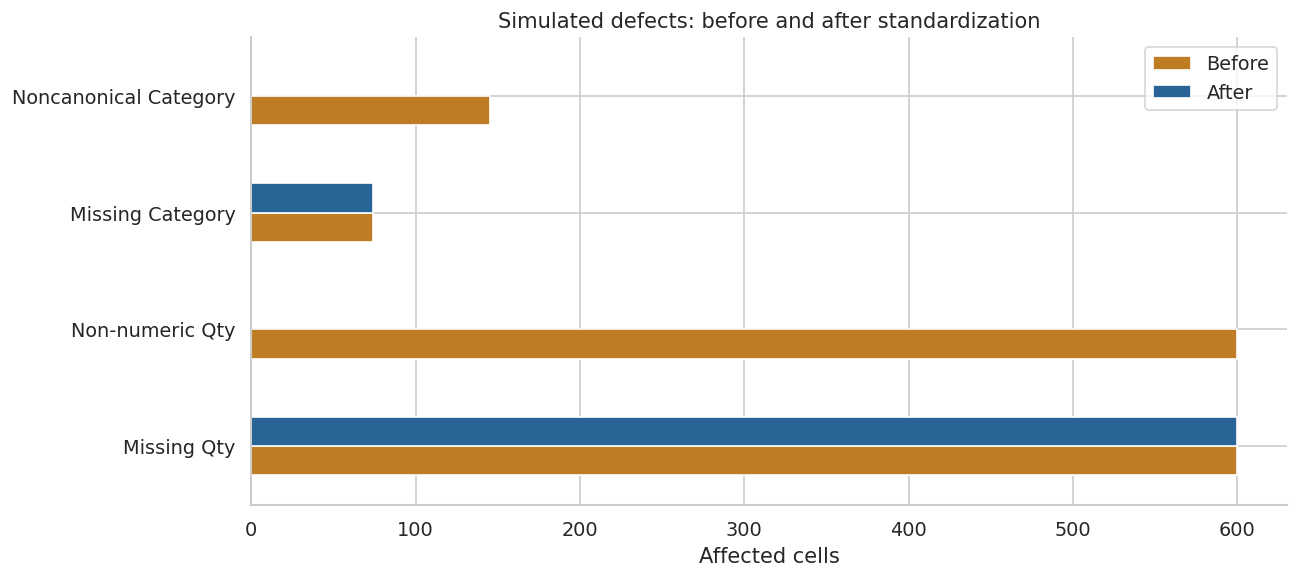

In [ ]:
qty_known = orders_clean["Qty"].notna()
cat_known = products_clean["Category"].notna()
assert orders_clean.loc[qty_known, "Qty"].astype(int).eq(orders_original.loc[qty_known, "Qty"]).all()
assert products_clean.loc[cat_known, "Category"].eq(products_original.loc[cat_known, "Category"]).all()
assert products_clean.loc[cat_known, "Category"].isin(allowed_categories).all()
quality_comparison = pd.DataFrame({
    "Issue": ["Missing Qty", "Non-numeric Qty", "Missing Category", "Noncanonical Category"],
    "Before": [orders_dirty["Qty"].isna().sum(),
               (orders_dirty["Qty"].notna() & pd.to_numeric(orders_dirty["Qty"], errors="coerce").isna()).sum(),
               products_dirty["Category"].isna().sum(),
               (products_dirty["Category"].notna() & ~products_dirty["Category"].isin(allowed_categories)).sum()],
    "After": [orders_clean["Qty"].isna().sum(), 0,
              products_clean["Category"].isna().sum(),
              (products_clean["Category"].notna() & ~products_clean["Category"].isin(allowed_categories)).sum()]
}).set_index("Issue")
display(quality_comparison)


**Result:** Numeric text and noncanonical category labels are corrected. Missing values remain unresolved at this stage and are addressed separately through source reconciliation.

### 4.5 Missing-Value Recovery
Missing quantities and categories are recovered from the original workbook using `OrderID` and `ProductID`, respectively. This is a keyed source lookup rather than statistical imputation. Recovery counts are reported, and the completed columns are reconciled against the source.

The resulting datasets are used for analysis. This preserves the source totals while retaining a separate standardized dataset containing the unresolved missing values.

In [13]:
orders_analysis = orders_clean.copy()
products_analysis = products_clean.copy()
qty_recovered = int(orders_analysis["Qty"].isna().sum())
category_recovered = int(products_analysis["Category"].isna().sum())
orders_analysis["Qty"] = orders_analysis["Qty"].fillna(orders_analysis["OrderID"].map(orders_original.set_index("OrderID")["Qty"]))
products_analysis["Category"] = products_analysis["Category"].fillna(products_analysis["ProductID"].map(products_original.set_index("ProductID")["Category"]))
assert orders_analysis["Qty"].astype(int).eq(orders_original["Qty"]).all()
assert products_analysis["Category"].eq(products_original["Category"]).all()
print(f"Recovered from untouched source: {qty_recovered} Qty cells; {category_recovered} Category cells.")
print("Final quantity total:", int(orders_analysis["Qty"].sum()))

Recovered from untouched source: 600 Qty cells; 74 Category cells.
Final quantity total: 867237


## 5. Data Integration and Metrics
### 5.1 Validated Joins
Order records are enriched through left joins to product, customer and location tables. Shipment records are linked to carrier attributes and order dates. Each join validates its many-to-one relationship, checks unmatched keys and confirms that the number of records is unchanged. Total revenue is reconciled before and after integration.

In [14]:
def checked_left_join(left, right, key, relationship="many_to_one"):
    merged = left.merge(right, on=key, how="left", validate=relationship, indicator=True)
    assert merged["_merge"].eq("both").all(), f"Unmatched values on {key}"
    assert len(merged) == len(left), f"Row multiplication on {key}"
    return merged.drop(columns="_merge")

sales = checked_left_join(orders_analysis, products_analysis[["ProductID", "Category", "Brand"]], "ProductID")
sales = checked_left_join(sales, customers[["CustomerID", "Segment", "LocationID"]], "CustomerID")
sales = checked_left_join(sales, locations[["LocationID", "Country", "Region"]], "LocationID")
delivery = checked_left_join(shipments, carriers[["CarrierID", "CarrierName", "Mode", "ServiceLevel"]], "CarrierID")
delivery = checked_left_join(delivery, orders_analysis[["OrderID", "OrderDate"]], "OrderID")
assert np.isclose(sales["Revenue"].sum(), orders_original["Revenue"].sum())
assert len(sales) == len(orders_original)
print("Sales rows:", len(sales), "Delivery rows:", len(delivery))

Sales rows: 60000 Delivery rows: 60000


### 5.2 Metric Definitions
| Metric | Calculation | Interpretation |
|---|---|---|
| Revenue | Sum of FactOrders.Revenue | Source monetary units (MU); currency is unspecified |
| Gross contribution proxy | Revenue − source Cost | Excludes freight, refunds and other unspecified expenses |
| Gross contribution margin | Sum(Revenue − Cost) / Sum(Revenue) | Ratio of totals, not an average of record-level margins |
| On-time delivery rate | Deliveries on or before PromisedDate / deliveries with valid dates | Calculated at shipment level |
| Delay among late shipments | DeliveryDate − PromisedDate, where the difference is positive | Describes late shipments only |

Order coverage ends in August 2026. Monetary aggregation assumes that source amounts are comparable; a common currency must be confirmed before cross-country totals support business decisions.

In [15]:
sales["GrossContribution"] = sales["Revenue"] - sales["Cost"]
sales["Year"] = sales["OrderDate"].dt.year
sales["Month"] = sales["OrderDate"].dt.month
sales["OrderMonth"] = sales["OrderDate"].dt.to_period("M").dt.to_timestamp()
delivery["Late"] = delivery["CalculatedDelayDays"].gt(0)
late_shipments = delivery.loc[delivery["Late"]]
source_period = f"{sales.OrderDate.min():%Y-%m-%d} to {sales.OrderDate.max():%Y-%m-%d}"
summary = pd.Series({"Order records": sales["OrderID"].nunique(),
    "Quantity units": sales["Qty"].sum(), "Revenue (MU)": sales["Revenue"].sum(),
    "Gross contribution proxy (MU)": sales["GrossContribution"].sum(),
    "Gross contribution margin (%)": 100*sales["GrossContribution"].sum()/sales["Revenue"].sum(),
    "Delivered shipments": len(delivery), "On-time delivery (%)": 100*delivery["CalculatedOnTime"].mean(),
    "Average delay among late shipments (days)": late_shipments["CalculatedDelayDays"].mean()})
print("Order coverage:", source_period)
display(summary.to_frame("Value"))

Order coverage: 2023-01-01 to 2026-08-31


,Value
Order records,"60,000.00"
Quantity units,"867,237.00"
Revenue (MU),"149,373,175.12"
Gross contribution proxy (MU),"36,199,544.10"
Gross contribution margin (%),24.23
Delivered shipments,"60,000.00"
On-time delivery (%),87.85
Average delay among late shipments (days),3.48


### 5.3 Feature Engineering

In [ ]:
# -------- Features from the Orders Table --------
sales["Quarter"] = sales["OrderDate"].dt.quarter
sales["DayOfWeek"] = sales["OrderDate"].dt.day_name()
sales["IsWeekend"] = sales["OrderDate"].dt.dayofweek.ge(5).astype(int)
sales["MarginPct"] = 100 * sales["GrossContribution"] / sales["Revenue"]
sales["DiscountBand"] = pd.cut(sales["Discount"],
                               bins=[-0.001, 0, 0.05, 0.10, 1.0],
                               labels=["None", "Low", "Medium", "High"])

# -------- Features from the Delivery Table --------
delivery["ProcessingDays"] = (delivery["ShipDate"] - delivery["OrderDate"]).dt.days
delivery["TransitDays"] = (delivery["DeliveryDate"] - delivery["ShipDate"]).dt.days
delivery["TotalLeadTimeDays"] = (delivery["DeliveryDate"] - delivery["OrderDate"]).dt.days
delivery["FreightPerKg"] = delivery["FreightCost"] / delivery["WeightKg"].replace(0, np.nan)

# -------- Merge All Features into One DataFrame --------
features = sales.merge(
    delivery[["OrderID", "ProcessingDays", "TransitDays", "TotalLeadTimeDays",
              "FreightPerKg", "CalculatedDelayDays", "Late", "Mode", "ServiceLevel"]],
    on="OrderID", how="left", validate="one_to_one")
features["IsReturned"] = features["OrderID"].isin(returns["OrderID"]).astype(int)

display(features.head())
print("Rows:", len(features), "| Columns:", features.shape[1])

## 6. Findings and Limitations
### 6.1 Summary of Results
The following summary is generated from the preceding calculations.

In [ ]:
display(Markdown(f"""
- **Coverage:** {len(sales):,} order records, {source_period}.
- **Delivery:** {delivery.CalculatedOnTime.mean():.1%} on-time across {len(delivery):,} recorded shipments.
- **Late severity:** {late_shipments["CalculatedDelayDays"].mean():.2f} mean days among {len(late_shipments):,} late shipments.
- **Data preparation:** Formatting defects were standardized; {qty_recovered} missing quantities and {category_recovered} missing categories were restored explicitly from the untouched source.
"""))


- **Coverage:** 60,000 order records, 2023-01-01 to 2026-08-31.
- **Comparable growth:** Jan–Aug 2026 revenue vs Jan–Aug 2025: +7.1%.
- **Largest revenue category:** Electronics, 25.4% of revenue.
- **Delivery:** 87.9% on-time across 60,000 recorded shipments.
- **Late severity:** 3.48 mean days among 7,289 late shipments.
- **Data preparation:** Formatting defects were standardized; 600 missing quantities and 74 missing categories were restored explicitly from the untouched source.


### 6.2 Limitations
- **Monetary comparability:** Currency is not specified. Totals use source monetary units under an assumption of comparability across records.
- **Contribution measure:** Revenue less Cost excludes freight, refunds, overhead and other undocumented expenses; it is not net profit.
- **Revenue reconciliation:** Differences from the displayed quantity-price-discount formula remain unexplained. Reported revenue is retained.
- **Time coverage:** Orders end in August 2026.
- **Data provenance:** Findings describe the supplied workbook. Scenario labels are present, and no fraud-based exclusions have been applied.
- **Payment information:** Missing payment dates remain unchanged pending a supported business rule or source record.

### 6.3 Areas for Further Investigation
Confirm currency and revenue definitions before financial interpretation.

### 6.4 Data Exports
The exported datasets distinguish simulated inputs (`dirty_simulated`), standardized data with unresolved missing values (`clean_unresolved`) and reconciled analysis inputs (`analysis_restored`). The audit log, workbook profile and KPI summary are saved to `outputs/`.

In [ ]:
orders_dirty.to_csv(OUT/"orders_dirty_simulated.csv",index=False)
products_dirty.to_csv(OUT/"products_dirty_simulated.csv",index=False)
orders_clean.to_csv(OUT/"orders_clean_unresolved.csv",index=False)
products_clean.to_csv(OUT/"products_clean_unresolved.csv",index=False)
orders_analysis.to_csv(OUT/"orders_analysis_restored.csv",index=False)
products_analysis.to_csv(OUT/"products_analysis_restored.csv",index=False)
audit_log.to_csv(OUT/"simulation_audit_log.csv",index=False)
features.to_csv(OUT/"features_final.csv", index=False)
profile.to_csv(OUT/"workbook_profile.csv",index=False)
summary.to_csv(OUT/"kpi_summary.csv",header=["Value"])
print("Exports written to:", OUT.as_posix())
print("Source unchanged:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())

Exports written to: outputs
Source unchanged: 37ece7e94427c9b16cd253c8d3de1292548b755377abed715cb677dbe37c0712


## 7. References
**Dataset:** `SupplyChain_Data.xlsx`. Workbook structure is reported in Section 2, and the file checksum is recorded in the setup output. All numerical results are calculated from this dataset.

**Technical documentation**
- [Pandas: Reading Excel workbooks](https://pandas.pydata.org/docs/reference/api/pandas.read_excel.html)
- [Pandas: Numeric conversion](https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html)
- [Pandas: DataFrame merge and relationship validation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html)
- [NumPy: Random number generation](https://numpy.org/doc/stable/reference/random/generator.html)
- [Project Jupyter: Documentation](https://docs.jupyter.org/en/latest/)